In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

# ==========================================
# 1. DATA GENERATION & PREPROCESSING
# ==========================================
print("Generating synthetic Credit Card transactions...")

# We create a dataset with 20 features (Amount, Time, Location_Score, etc.)
# n_classes=2 means (0: Legit, 1: Fraud)
# weights=[0.95, 0.05] simulates that Fraud is rare (only 5% of data)
X, y = make_classification(n_samples=5000, n_features=20, n_informative=10,
                           n_classes=2, weights=[0.95, 0.05], random_state=42)

# Split into Training (to learn) and Testing (to evaluate)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# CRITICAL STEP: Standardization
# Neural Networks struggle if inputs are different scales (e.g. Age=30 vs Salary=50000)
# This scales everything to be roughly between -1 and 1
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert numpy arrays to PyTorch tensors (float32 is standard for AI)
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1) # Shape becomes [N, 1]
X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

# ==========================================
# 2. DEFINE THE DEEP MLP ARCHITECTURE
# ==========================================
class FraudDetectorMLP(nn.Module):
    def __init__(self):
        super(FraudDetectorMLP, self).__init__()

        # We use nn.Sequential to stack layers neatly
        self.network = nn.Sequential(
            # --- Input Layer ---
            # Takes 20 input features (columns in our data)
            nn.Linear(20, 64),
            nn.ReLU(),  # Activation function to learn non-linear patterns

            # --- Hidden Layer 1 (The "Feature Extractor") ---
            # Compressing info from 64 -> 32 neurons
            nn.Linear(64, 32),
            nn.ReLU(),

            # --- Hidden Layer 2 (The "Decision Refiner") ---
            # Compressing info from 32 -> 16 neurons
            nn.Linear(32, 16),
            nn.ReLU(),

            # --- Output Layer ---
            # 16 -> 1 neuron (The final score)
            nn.Linear(16, 1),

            # Sigmoid squashes the output between 0 and 1 (Probability of Fraud)
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x)

# Initialize Model
model = FraudDetectorMLP()
print("Model Architecture Created:")
print(model)

# ==========================================
# 3. DEFINE LOSS AND OPTIMIZER
# ==========================================
# Binary Cross Entropy (BCELoss) is the standard math for Yes/No classification
criterion = nn.BCELoss()

# Adam is a "smart" optimizer (better than basic SGD) that adjusts Learning Rate automatically
optimizer = optim.Adam(model.parameters(), lr=0.001)

# ==========================================
# 4. TRAINING LOOP
# ==========================================
print("\nStarting Training...")
EPOCHS = 20

for epoch in range(EPOCHS):
    # A. Forward Pass
    predictions = model(X_train)

    # B. Calculate Error
    loss = criterion(predictions, y_train)

    # C. Backward Pass (Backpropagation)
    optimizer.zero_grad() # Reset gradients
    loss.backward()       # Calculate new gradients
    optimizer.step()      # Update weights

    if (epoch+1) % 5 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} | Loss: {loss.item():.4f}")

# ==========================================
# 5. EVALUATION
# ==========================================
print("\nEvaluating on Test Data...")

# Turn off gradient calculation for testing (saves memory)
with torch.no_grad():
    test_predictions = model(X_test)

    # Convert probabilities to Yes/No (Threshold 0.5)
    predicted_classes = (test_predictions > 0.5).float()

    # Calculate Accuracy
    correct_predictions = (predicted_classes == y_test).sum()
    accuracy = correct_predictions / y_test.shape[0]

    print(f"Test Accuracy: {accuracy.item() * 100:.2f}%")

    # Manual check of first 5 cases
    print("\nSample Predictions (First 5 users):")
    for i in range(5):
        actual = "FRAUD" if y_test[i].item() == 1 else "Legit"
        pred = "FRAUD" if predicted_classes[i].item() == 1 else "Legit"
        prob = test_predictions[i].item()
        print(f"Case {i+1}: Actual: {actual} | Predicted: {pred} (Confidence: {prob:.4f})")

Generating synthetic Credit Card transactions...
Model Architecture Created:
FraudDetectorMLP(
  (network): Sequential(
    (0): Linear(in_features=20, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=1, bias=True)
    (7): Sigmoid()
  )
)

Starting Training...
Epoch 5/20 | Loss: 0.5773
Epoch 10/20 | Loss: 0.5451
Epoch 15/20 | Loss: 0.5067
Epoch 20/20 | Loss: 0.4593

Evaluating on Test Data...
Test Accuracy: 94.80%

Sample Predictions (First 5 users):
Case 1: Actual: Legit | Predicted: Legit (Confidence: 0.3646)
Case 2: Actual: Legit | Predicted: Legit (Confidence: 0.3418)
Case 3: Actual: Legit | Predicted: Legit (Confidence: 0.3456)
Case 4: Actual: Legit | Predicted: Legit (Confidence: 0.3453)
Case 5: Actual: Legit | Predicted: Legit (Confidence: 0.3714)


--- DATA PREPARATION ---
Loading real data from fraudTest.csv...
Target Column Detected: 'is_fraud'
Automatically dropped non-numeric columns: ['category', 'state', 'city', 'street', 'trans_num', 'first', 'job', 'gender', 'dob', 'trans_date_trans_time', 'merchant', 'last']
Real data loaded: 555719 transactions with 10 numeric features.

Model initialized for 10 input features.

--- STARTING TRAINING ---
Epoch 5/50 | Train Loss: 0.6758 | Val Loss: 0.6711
Epoch 10/50 | Train Loss: 0.6501 | Val Loss: 0.6439
Epoch 15/50 | Train Loss: 0.6141 | Val Loss: 0.6055
Epoch 20/50 | Train Loss: 0.5653 | Val Loss: 0.5542
Epoch 25/50 | Train Loss: 0.5041 | Val Loss: 0.4906
Epoch 30/50 | Train Loss: 0.4303 | Val Loss: 0.4146
Epoch 35/50 | Train Loss: 0.3471 | Val Loss: 0.3305
Epoch 40/50 | Train Loss: 0.2625 | Val Loss: 0.2468
Epoch 45/50 | Train Loss: 0.1866 | Val Loss: 0.1736
Epoch 50/50 | Train Loss: 0.1272 | Val Loss: 0.1180

Generating Learning Curves...


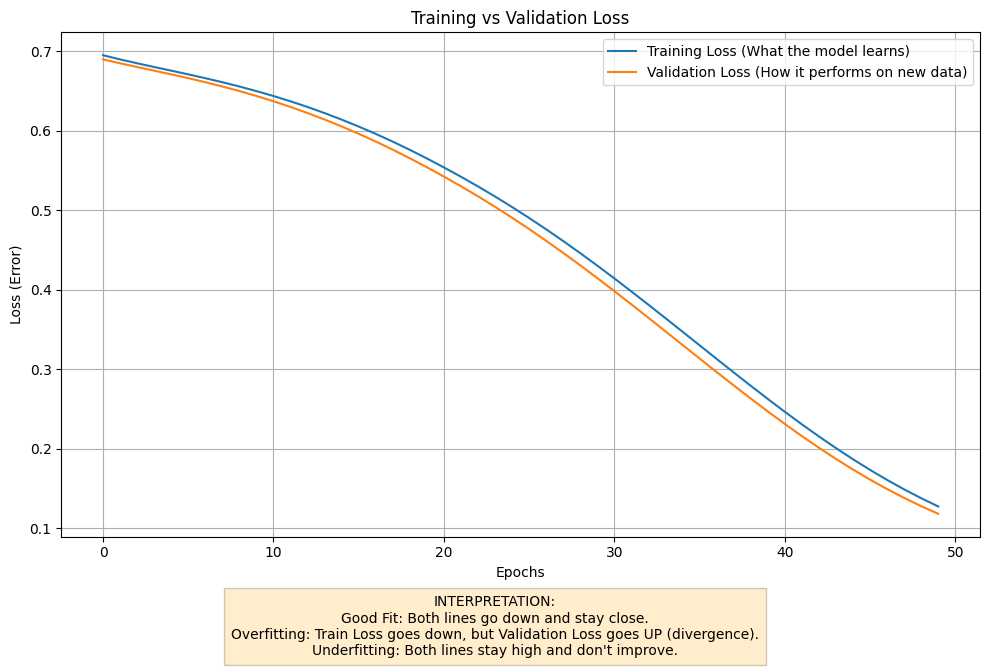


Final Test Accuracy: 99.62%


In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# ==========================================
# 1. DATA GENERATION & PREPROCESSING
# ==========================================
print("--- DATA PREPARATION ---")

# List of possible filenames to look for
possible_files = ['fraudTest.csv', 'creditcard.csv', 'fraud_data.csv']
data_file = None

for f in possible_files:
    if os.path.exists(f):
        data_file = f
        break

if data_file:
    print(f"Loading real data from {data_file}...")
    df = pd.read_csv(data_file)

    # --- STEP 1: Smart Target Detection ---
    # Different datasets use different names for the "Fraud" label
    possible_targets = ['is_fraud', 'Class', 'fraud', 'Target', 'Label']
    target_col = None

    for col in possible_targets:
        if col in df.columns:
            target_col = col
            break

    if target_col is None:
        # Fallback: assume the last column is the target if named 'target' isn't found
        print(f"Warning: Specific target column name not found. Using last column: {df.columns[-1]}")
        target_col = df.columns[-1]

    print(f"Target Column Detected: '{target_col}'")

    # --- STEP 2: Handle Non-Numeric Data ---
    # Neural Networks only understand numbers.
    # 'creditcard.csv' is all numbers, but 'fraudTest.csv' has strings (Merchant names, etc.)
    # We must drop string columns or the code will crash later.

    # Separate Y (Target)
    y = df[target_col].values

    # Separate X (Features)
    X_raw = df.drop(target_col, axis=1)

    # Keep only numeric columns
    X_numeric = X_raw.select_dtypes(include=[np.number])

    # Report what we dropped
    dropped_cols = list(set(X_raw.columns) - set(X_numeric.columns))
    if dropped_cols:
        print(f"Automatically dropped non-numeric columns: {dropped_cols}")

    X = X_numeric.values

    print(f"Real data loaded: {X.shape[0]} transactions with {X.shape[1]} numeric features.")

else:
    print(f"No data file found (checked: {possible_files}).")
    print("Generating synthetic data instead (fallback mode)...")

    # Create dataset with 30 features
    X, y = make_classification(n_samples=10000, n_features=30, n_informative=20,
                               n_classes=2, weights=[0.99, 0.01], random_state=42)

# Split into Training and Testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardization
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert to PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

# ==========================================
# 2. DEFINE THE DEEP MLP ARCHITECTURE
# ==========================================
class FraudDetectorMLP(nn.Module):
    def __init__(self, input_dim):
        super(FraudDetectorMLP, self).__init__()

        self.network = nn.Sequential(
            # Input Layer (Dynamic size based on dataset)
            nn.Linear(input_dim, 64),
            nn.ReLU(),

            # Hidden Layer 1
            nn.Linear(64, 32),
            nn.ReLU(),

            # Hidden Layer 2
            nn.Linear(32, 16),
            nn.ReLU(),

            # Output Layer
            nn.Linear(16, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x)

# Initialize Model (Pass number of features dynamically)
input_features = X_train.shape[1]
model = FraudDetectorMLP(input_features)
print(f"\nModel initialized for {input_features} input features.")

# ==========================================
# 3. DEFINE LOSS AND OPTIMIZER
# ==========================================
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# ==========================================
# 4. TRAINING LOOP WITH MONITORING
# ==========================================
print("\n--- STARTING TRAINING ---")
EPOCHS = 50  # Increased epochs to potentially see overfitting
train_losses = []
val_losses = []

for epoch in range(EPOCHS):
    model.train() # Set to training mode

    # A. Forward Pass
    predictions = model(X_train)
    loss = criterion(predictions, y_train)

    # B. Backward Pass
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # C. Validation Step (Track Overfitting)
    model.eval() # Set to evaluation mode (stops dropout, etc.)
    with torch.no_grad():
        val_predictions = model(X_test)
        val_loss = criterion(val_predictions, y_test)

    # Store history
    train_losses.append(loss.item())
    val_losses.append(val_loss.item())

    if (epoch+1) % 5 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {loss.item():.4f} | Val Loss: {val_loss.item():.4f}")

# ==========================================
# 5. VISUALIZATION OF FITTING
# ==========================================
print("\nGenerating Learning Curves...")

plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='Training Loss (What the model learns)')
plt.plot(val_losses, label='Validation Loss (How it performs on new data)')
plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss (Error)')
plt.legend()
plt.grid(True)

# Explanation annotation
plt.figtext(0.5, -0.1,
            "INTERPRETATION:\n"
            "Good Fit: Both lines go down and stay close.\n"
            "Overfitting: Train Loss goes down, but Validation Loss goes UP (divergence).\n"
            "Underfitting: Both lines stay high and don't improve.",
            ha="center", fontsize=10, bbox={"facecolor":"orange", "alpha":0.2, "pad":5})

plt.tight_layout()
plt.show()

# ==========================================
# 6. FINAL EVALUATION
# ==========================================
with torch.no_grad():
    final_preds = model(X_test)
    predicted_classes = (final_preds > 0.5).float()
    accuracy = (predicted_classes == y_test).sum() / y_test.shape[0]
    print(f"\nFinal Test Accuracy: {accuracy.item() * 100:.2f}%")